In [1]:
import geopandas as gpd
import pandas as pd
import matplotlib.pyplot as plt

In [2]:
districts = gpd.read_file("Districts.geojson")
districts.head()

,District,Zone,geometry
0,North_A,North,"POLYGON ((0 0, 1 0, 1 1, 0 1, 0 0))"
1,North_B,North,"POLYGON ((1 0, 2 0, 2 1, 1 1, 1 0))"
2,North_C,North,"POLYGON ((2 0, 3 0, 3 1, 2 1, 2 0))"
3,Central_A,Central,"POLYGON ((0 1, 1 1, 1 2, 0 2, 0 1))"
4,Central_B,Central,"POLYGON ((1 1, 2 1, 2 2, 1 2, 1 1))"


In [3]:
print("Shape:", districts.shape)

print("\nColumns:")
print(districts.columns)

print("\nGeometry types:")
print(districts.geom_type.value_counts())

print("\nCRS:")
print(districts.crs)

Shape: (9, 3)

Columns:
Index(['District', 'Zone', 'geometry'], dtype='str')

Geometry types:
Polygon    9
Name: count, dtype: int64

CRS:
EPSG:4326


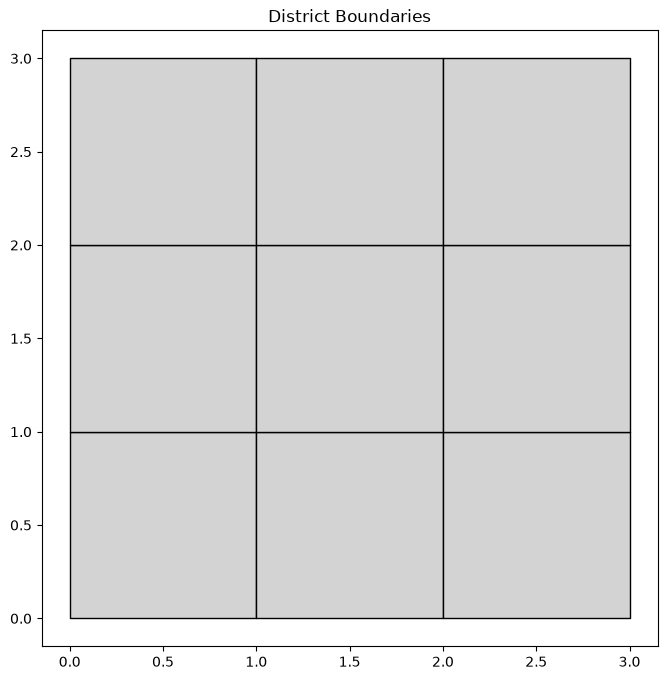

In [4]:
districts.plot(
    figsize=(8, 8),
    edgecolor="black",
    facecolor="lightgray"
)

plt.title("District Boundaries")
plt.show()

In [5]:
stations = gpd.read_file("Rainfall_Stations.geojson")
stations.head()

,Station,Longitude,Latitude,Rainfall_mm,geometry
0,Station_01,0.25,0.25,812,POINT (0.25 0.25)
1,Station_02,0.70,0.65,756,POINT (0.7 0.65)
2,Station_03,1.30,0.30,923,POINT (1.3 0.3)
3,Station_04,1.75,0.75,1012,POINT (1.75 0.75)
4,Station_05,2.40,0.40,684,POINT (2.4 0.4)


In [6]:
print("Shape:", stations.shape)

print("\nColumns:")
print(stations.columns)

print("\nGeometry types:")
print(stations.geom_type.value_counts())

print("\nCRS:")
print(stations.crs)

Shape: (24, 5)

Columns:
Index(['Station', 'Longitude', 'Latitude', 'Rainfall_mm', 'geometry'], dtype='str')

Geometry types:
Point    24
Name: count, dtype: int64

CRS:
EPSG:4326


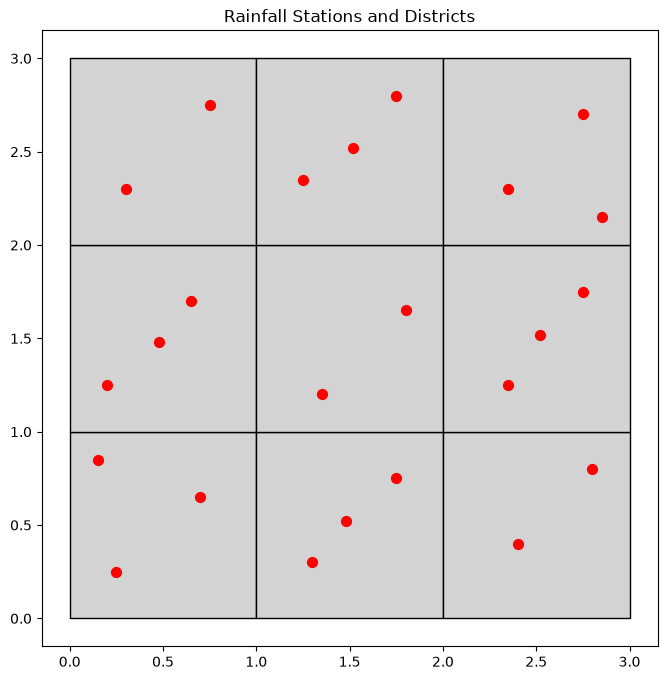

In [7]:
fig, ax = plt.subplots(figsize=(9, 8))

districts.plot(
    ax=ax,
    edgecolor="black",
    facecolor="lightgray"
)

stations.plot(
    ax=ax,
    color="red",
    markersize=50
)

plt.title("Rainfall Stations and Districts")
plt.show()

In [8]:
station_district = gpd.sjoin(
    stations,
    districts,
    predicate="within"
)

station_district.head()

,Station,Longitude,Latitude,Rainfall_mm,geometry,index_right,District,Zone
0,Station_01,0.25,0.25,812,POINT (0.25 0.25),0,North_A,North
1,Station_02,0.70,0.65,756,POINT (0.7 0.65),0,North_A,North
2,Station_03,1.30,0.30,923,POINT (1.3 0.3),1,North_B,North
3,Station_04,1.75,0.75,1012,POINT (1.75 0.75),1,North_B,North
4,Station_05,2.40,0.40,684,POINT (2.4 0.4),2,North_C,North


In [9]:
station_district.columns

Index(['Station', 'Longitude', 'Latitude', 'Rainfall_mm', 'geometry',
       'index_right', 'District', 'Zone'],
      dtype='str')

In [10]:
station_district[
    ["Station", "Rainfall_mm", "District", "Zone"]
]

,Station,Rainfall_mm,District,Zone
0,Station_01,812,North_A,North
1,Station_02,756,North_A,North
2,Station_03,923,North_B,North
3,Station_04,1012,North_B,North
4,Station_05,684,North_C,North
5,Station_06,731,North_C,North
6,Station_07,845,Central_A,Central
7,Station_08,902,Central_A,Central
8,Station_09,978,Central_B,Central
9,Station_10,1054,Central_B,Central


In [11]:
station_district[
    station_district["Station"] == "Station_01"
]


,Station,Longitude,Latitude,Rainfall_mm,geometry,index_right,District,Zone
0,Station_01,0.25,0.25,812,POINT (0.25 0.25),0,North_A,North


In [12]:
station_district["District"].value_counts()

District
North_A      3
North_B      3
Central_A    3
Central_C    3
South_B      3
South_C      3
North_C      2
Central_B    2
South_A      2
Name: count, dtype: int64

In [13]:
district_rainfall = (
    station_district
    .groupby("District")["Rainfall_mm"]
    .mean()
    .reset_index()
)

district_rainfall

,District,Rainfall_mm
0,Central_A,898.000000
1,Central_B,1016.000000
2,Central_C,830.666667
3,North_A,780.333333
4,North_B,975.000000
5,North_C,707.500000
6,South_A,768.000000
7,South_B,1018.333333
8,South_C,853.333333


In [14]:
district_max_rainfall = (
    station_district
    .groupby("District")["Rainfall_mm"]
    .max()
    .reset_index()
)

district_max_rainfall

,District,Rainfall_mm
0,Central_A,947
1,Central_B,1054
2,Central_C,865
3,North_A,812
4,North_B,1012
5,North_C,731
6,South_A,815
7,South_B,1088
8,South_C,917


In [15]:
district_min_rainfall =(
    station_district
    .groupby("District")["Rainfall_mm"]
    .min()
    .reset_index()
)
district_min_rainfall

,District,Rainfall_mm
0,Central_A,845
1,Central_B,978
2,Central_C,799
3,North_A,756
4,North_B,923
5,North_C,684
6,South_A,721
7,South_B,936
8,South_C,754


In [16]:
districts_rainfall = districts.merge(
    district_rainfall,
    on="District",
    how="left"
)

districts_rainfall.head()


,District,Zone,geometry,Rainfall_mm
0,North_A,North,"POLYGON ((0 0, 1 0, 1 1, 0 1, 0 0))",780.333333
1,North_B,North,"POLYGON ((1 0, 2 0, 2 1, 1 1, 1 0))",975.000000
2,North_C,North,"POLYGON ((2 0, 3 0, 3 1, 2 1, 2 0))",707.500000
3,Central_A,Central,"POLYGON ((0 1, 1 1, 1 2, 0 2, 0 1))",898.000000
4,Central_B,Central,"POLYGON ((1 1, 2 1, 2 2, 1 2, 1 1))",1016.000000


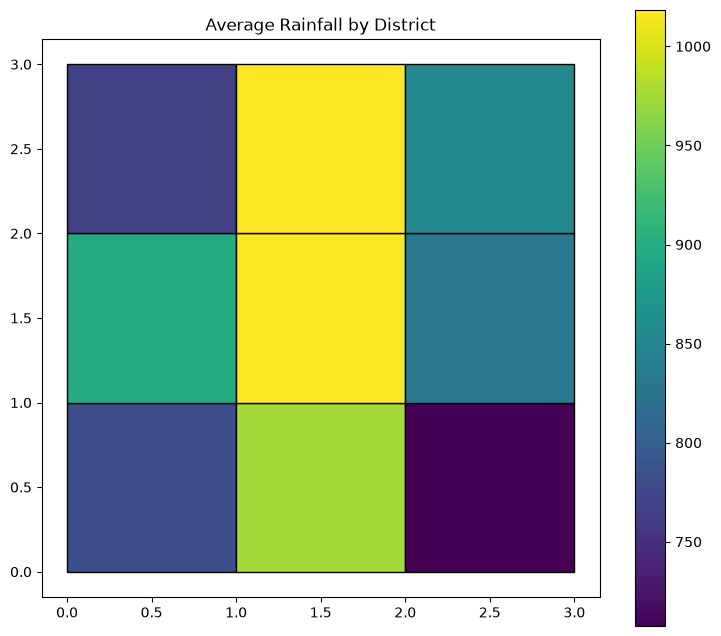

In [17]:
fig, ax = plt.subplots(figsize=(9, 8))

districts_rainfall.plot(
    column="Rainfall_mm",
    ax=ax,
    legend=True,
    edgecolor="black"
)

plt.title("Average Rainfall by District")
plt.show()

In [18]:
stations_projected = stations.to_crs("EPSG:3857")

print("Projected CRS:", stations_projected.crs)


Projected CRS: EPSG:3857


In [19]:
target = stations_projected[
    stations_projected["Station"] == "Station_01"
].copy()

other_stations = stations_projected[
    stations_projected["Station"] != "Station_01"
].copy()

In [20]:
target = target.rename(
    columns={"Station": "Target_Station"}
)

other_stations = other_stations.rename(
    columns={"Station": "Nearest_Station"}
)

nearest_station = gpd.sjoin_nearest(
    target,
    other_stations,
    how="left",
    distance_col="Distance_m"
)

nearest_station[
    ["Target_Station", "Nearest_Station", "Distance_m"]
]

,Target_Station,Nearest_Station,Distance_m
0,Station_01,Station_02,67024.181364


In [21]:
district_summary = (
    station_district
    .groupby("District")
    .agg(
        Station_Count=("Station", "count"),
        Average_Rainfall_mm=("Rainfall_mm", "mean"),
        Maximum_Rainfall_mm=("Rainfall_mm", "max"),
        Minimum_Rainfall_mm=("Rainfall_mm", "min")
    )
    .reset_index()
)

district_summary

,District,Station_Count,Average_Rainfall_mm,Maximum_Rainfall_mm,Minimum_Rainfall_mm
0,Central_A,3,898.000000,947,845
1,Central_B,2,1016.000000,1054,978
2,Central_C,3,830.666667,865,799
3,North_A,3,780.333333,812,756
4,North_B,3,975.000000,1012,923
5,North_C,2,707.500000,731,684
6,South_A,2,768.000000,815,721
7,South_B,3,1018.333333,1088,936
8,South_C,3,853.333333,917,754


In [22]:
districts_final = districts.merge(
    district_summary,
    on="District",
    how="left"
)

districts_final.head()

,District,Zone,geometry,Station_Count,Average_Rainfall_mm,Maximum_Rainfall_mm,Minimum_Rainfall_mm
0,North_A,North,"POLYGON ((0 0, 1 0, 1 1, 0 1, 0 0))",3,780.333333,812,756
1,North_B,North,"POLYGON ((1 0, 2 0, 2 1, 1 1, 1 0))",3,975.000000,1012,923
2,North_C,North,"POLYGON ((2 0, 3 0, 3 1, 2 1, 2 0))",2,707.500000,731,684
3,Central_A,Central,"POLYGON ((0 1, 1 1, 1 2, 0 2, 0 1))",3,898.000000,947,845
4,Central_B,Central,"POLYGON ((1 1, 2 1, 2 2, 1 2, 1 1))",2,1016.000000,1054,978


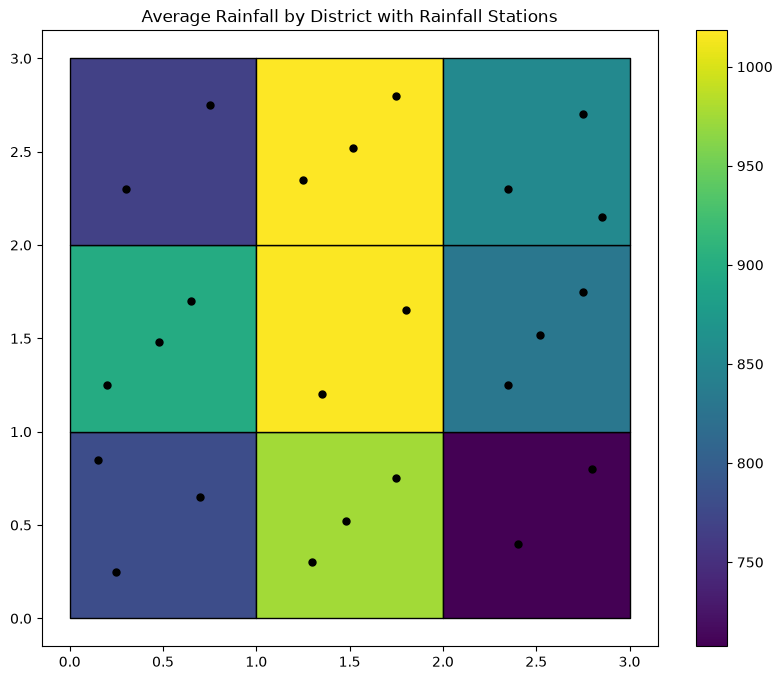

In [23]:
fig, ax = plt.subplots(figsize=(10, 8))

districts_final.plot(
    column="Average_Rainfall_mm",
    ax=ax,
    legend=True,
    edgecolor="black"
)

stations.plot(
    ax=ax,
    color="black",
    markersize=25
)

plt.title("Average Rainfall by District with Rainfall Stations")
plt.show()

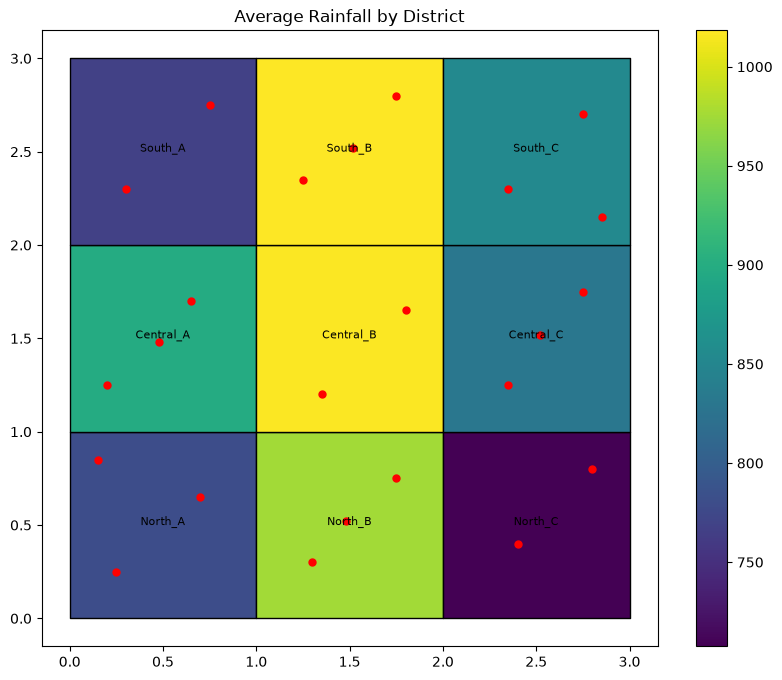

In [29]:
fig, ax = plt.subplots(figsize=(10, 8))

districts_final.plot(
    column="Average_Rainfall_mm",
    ax=ax,
    legend=True,
    edgecolor="black"
)

stations.plot(
    ax=ax,
    color="Red",
    markersize=25
)

for idx, row in districts_final.iterrows():
    point = row.geometry.centroid

    ax.text(
        point.x,
        point.y,
        row["District"],
        ha="center",
        fontsize=8
    )

plt.title("Average Rainfall by District")
plt.show()

In [25]:
station_district.to_file(
    "Rainfall_Stations_With_District.geojson",
    driver="GeoJSON"
)

In [26]:
districts_final.to_file(
    "District_Rainfall_Analysis.geojson",
    driver="GeoJSON"
)

In [27]:
district_summary.to_csv(
    "District_Rainfall_Summary.csv",
    index=False
)


In [28]:
district_summary.loc[
    district_summary["Average_Rainfall_mm"].idxmax()
]

District                   South_B
Station_Count                    3
Average_Rainfall_mm    1018.333333
Maximum_Rainfall_mm           1088
Minimum_Rainfall_mm            936
Name: 7, dtype: object